# Sampling och variation

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(0)
true_mean, true_sd = 7000, 1800

# generates a population of 1,000,000 normally distributed values with a mean of 7000 and a standard deviation of 1800
pop = np.random.normal(true_mean, true_sd, 1000000)
pd.Series(pop).describe()

count    1000000.000000
mean        7002.721864
std         1799.859287
min        -2004.137572
25%         5787.607348
50%         7004.297915
75%         8216.303397
max        15489.991876
dtype: float64

## Vanliga statistiska symboler
I statistiska texter och formler används ofta följande symboler:
- n är antalet observationer i stickprovet.
- μ (grekiska bokstaven my) är populationens verkliga medelvärde. Det är vanligtvis okänt.
- x̄ (x-streck) är stickprovets medelvärde och används för att uppskatta μ.
- s är stickprovets standardavvikelse.
- SE är standardfelet och beskriver hur mycket en skattning, exempelvis stickprovsmedelvärdet, förväntas variera mellan olika stickprov.

## Standardavvikelse och standardfel
Standardavvikelse och standardfel beskriver två olika sorters variation.
- Standardavvikelsen beskriver hur mycket de enskilda observationerna varierar inom populationen eller stickprovet.  
  
- Standardfelet beskriver hur mycket ett beräknat värde, exempelvis stickprovsmedelvärdet, förväntas variera mellan olika stickprov.  

För ett **medelvärde** kan **standardfelet** uppskattas med:  
standardfel = stickprovets standardavvikelse / √antal observationer  
eller kortare:  
SE = s / √n  
När urvalsstorleken n ökar blir standardfelet mindre. Stickprovsmedelvärdet blir då vanligtvis mer precist och varierar mindre mellan olika stickprov.  
Sambandet innehåller en kvadratrot. För att ungefär halvera standardfelet behöver vi därför fyra gånger så många observationer.

### Stickprovsstorlek och representativitet
Ett större stickprov minskar den slumpmässiga variationen, men löser inte alla problem.  
Om urvalet är systematiskt snedvridet kan även ett mycket stort stickprov ge en missvisande uppskattning.   
Exempelvis hjälper det inte att fråga fler personer om alla tillfrågade kommer från samma begränsade grupp.  
Det är därför viktigt att skilja mellan:  
- precision: hur mycket resultatet varierar mellan stickprov  
- bias eller systematiskt fel: att urvalsmetoden tenderar att ge ett resultat som ligger åt fel håll
  
Standardfelet beskriver precisionen. Det visar inte om urvalet är representativt.

In [18]:
def sample_mean(n):
    return np.mean(np.random.choice(pop, size=n, replace=True)) 
# replace ska vara False om man vill ha sampling utan återläggning, True för med återläggning, stor skillnad i hastighet

R = 2000
mean_n30 = np.array([sample_mean(30) for _ in range(R)])
mean_n200 = np.array([sample_mean(200) for _ in range(R)])


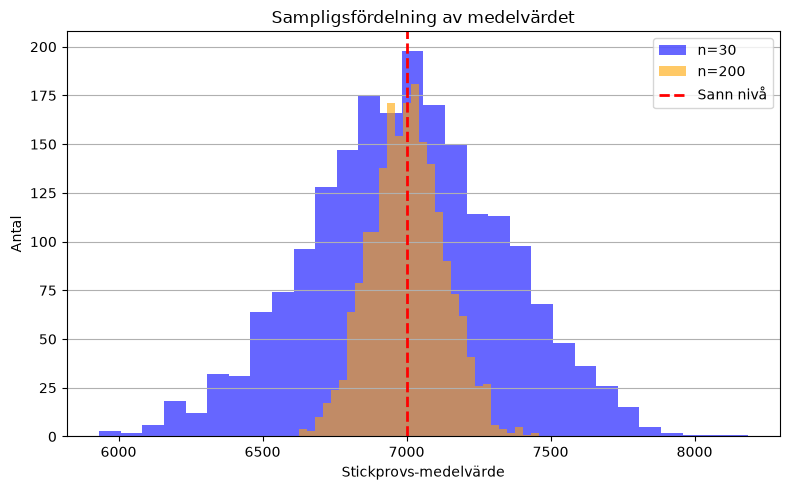

In [19]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(mean_n30, bins=30, alpha=0.6, label='n=30', color='blue')
ax.hist(mean_n200, bins=30, alpha=0.6, label='n=200', color='orange')
ax.axvline(true_mean, color='red', linestyle='--', linewidth=2, label='Sann nivå')
ax.set_title('Sampligsfördelning av medelvärdet')
ax.set_xlabel('Stickprovs-medelvärde')
ax.set_ylabel('Antal')
ax.grid(True, axis='y')
ax.legend()
plt.tight_layout()
plt.show()


### Uträkning av standardfel

In [ ]:
sd = np.std(pop, ddof=1)
SE_n30 = sd / np.sqrt(30)
SE_n200 = sd / np.sqrt(200)
print(f"Standard error for n=30: {SE_n30:.2f}")
print(f"Standard error for n=200: {SE_n200:.2f}")

Standard error for n=30: 328.61
Standard error for n=200: 127.27


### Uträkning av konfidensintervall

In [ ]:
def ci_95(x):
    m = x.mean()
    s = x.std(ddof=1)
    se = s / np.sqrt(len(x))
    z = 1.96  # z-score for 95% confidence
    return m - z * se, m + z * se
# confidence interval is low: m-z*se, high: m+z*se

def coverage(n, R=1000):
    ok = 0
    for _ in range(R):
        x = np.random.choice(pop, size=n, replace=False)
        lo, hi = ci_95(pd.Series(x))
        ok += (lo <= true_mean <= hi)
    return ok / R

coverage(30), coverage(200)


(np.float64(0.934), np.float64(0.951))

### P-värde i ett permutationstest
Det visar hur stor andel av de simulerade permutationerna som gav en skillnad mellan   gruppernas medelvärden som var minst lika extrem som den observerade skillnaden (obs).

In [30]:
A = np.random.choice(pop, size=60, replace=False)
B = np.random.choice(pop, size=60, replace=False)

obs = B.mean() - A.mean()
all_vals = np.concatenate([A, B])
nA = len(A)
R = 5000
perm  = np.empty(R)
for i in range(R):
    np.random.shuffle(all_vals)
    perm[i] = all_vals[nA:].mean() - all_vals[:nA].mean()
p = np.mean(np.abs(perm) >= np.abs(obs))
p


np.float64(0.8518)